In [5]:
%pip install pandas pyarrow numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:

# ================================================================
# NFL OFFENSIVE PLAY STYLE CLUSTERING AND EPA PER DRIVE PREDICTION
# Seasons: 2018–2024
# ================================================================
#
# Data source: nflfastR / nflverse
# Methods: Feature Engineering, K-Means, PCA, Ridge Regression,
#          Cross-Validation, Temporal Stability, Playoff Analysis
#
# Required packages:
# pip install pandas pyarrow numpy scikit-learn matplotlib seaborn
#
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler



In [7]:
# ================================================================
# 1. CONFIGURATION
# ================================================================

DATA_DIR = Path(
    "C:/Users/jbenitez/Downloads/Data Mining NFL Project"
)

OUTPUT_DIR = DATA_DIR / "nfl_project_outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SEASONS = range(2018, 2025)
RANDOM_STATE = 42

FEATURES = [
    "pass_rate",
    "early_down_pass_rate",
    "success_rate",
    "epa_per_play",
    "fourth_down_go_rate",
    "avg_air_yards",
    "avg_yac",
    "shotgun_rate",
    "no_huddle_rate"
]

REQUIRED_COLUMNS = [
    "season", "season_type", "posteam", "defteam",
    "play_type", "epa", "game_id", "drive",
    "down", "ydstogo", "air_yards",
    "yards_after_catch", "shotgun",
    "no_huddle", "success"
]

sns.set_theme(style="whitegrid")

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / name, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()




In [8]:
# ================================================================
# 2. LOAD NFL PLAY-BY-PLAY DATA
# ================================================================

frames = []

for season in SEASONS:

    file_path = DATA_DIR / f"play_by_play_{season}.parquet"

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing file: {file_path}"
        )

    df = pd.read_parquet(file_path)

    missing = sorted(set(REQUIRED_COLUMNS) - set(df.columns))

    if missing:
        raise ValueError(
            f"{file_path.name} is missing columns: {missing}"
        )

    frames.append(df)

    print(f"{season}: {len(df):,} rows loaded")

pbp = pd.concat(frames, ignore_index=True)

print("\nTotal plays loaded:", f"{len(pbp):,}")




2018: 47,109 rows loaded
2019: 47,260 rows loaded
2020: 47,705 rows loaded
2021: 49,922 rows loaded
2022: 49,434 rows loaded
2023: 49,665 rows loaded
2024: 49,492 rows loaded

Total plays loaded: 340,587


In [9]:
# ================================================================
# 3. DATA CLEANING
# ================================================================

regular = pbp[
    pbp["season_type"] == "REG"
].copy()

offense = regular[
    regular["play_type"].isin(["pass", "run"])
    & regular["epa"].notna()
    & regular["posteam"].notna()
].copy()

offense["is_pass"] = (
    offense["play_type"] == "pass"
).astype(float)

offense["early_down"] = offense["down"].isin([1, 2])

offense["early_pass"] = (
    offense["early_down"]
    & (offense["play_type"] == "pass")
)

offense["fourth_go"] = offense["down"] == 4

for column in [
    "success", "shotgun", "no_huddle",
    "air_yards", "yards_after_catch"
]:
    offense[column] = pd.to_numeric(
        offense[column], errors="coerce"
    )

print("Eligible offensive plays:", f"{len(offense):,}")




Eligible offensive plays: 231,945


In [10]:
# ================================================================
# 4. TEAM-SEASON FEATURE ENGINEERING
# ================================================================

keys = ["season", "posteam"]

team = offense.groupby(keys).agg(
    plays=("epa", "size"),
    pass_plays=("is_pass", "sum"),
    early_down_plays=("early_down", "sum"),
    early_passes=("early_pass", "sum"),
    success_rate=("success", "mean"),
    epa_per_play=("epa", "mean"),
    fourth_go=("fourth_go", "sum"),
    avg_air_yards=("air_yards", "mean"),
    avg_yac=("yards_after_catch", "mean"),
    shotgun_rate=("shotgun", "mean"),
    no_huddle_rate=("no_huddle", "mean")
).reset_index()

team["pass_rate"] = (
    team["pass_plays"] / team["plays"]
)

team["early_down_pass_rate"] = (
    team["early_passes"]
    / team["early_down_plays"].replace(0, np.nan)
)

# Fourth-down offensive attempts divided by all eligible
# offensive plays. This is NOT a fourth-down conversion rate.
team["fourth_down_go_rate"] = (
    team["fourth_go"] / team["plays"]
)

# EPA per drive
# Sum eligible offensive EPA within each game/drive,
# then average those drive totals for each team-season.

drives = offense.groupby(
    keys + ["game_id", "drive"]
)["epa"].sum().reset_index(name="drive_epa")

drive_summary = drives.groupby(keys)[
    "drive_epa"
].mean().reset_index(name="epa_per_drive")

team = team.merge(
    drive_summary,
    on=keys,
    validate="one_to_one"
)

print("\nTeam-season dataset shape:", team.shape)

display(team.head())





Team-season dataset shape: (224, 17)


,season,posteam,plays,pass_plays,early_down_plays,early_passes,success_rate,epa_per_play,fourth_go,avg_air_yards,avg_yac,shotgun_rate,no_huddle_rate,pass_rate,early_down_pass_rate,fourth_down_go_rate,epa_per_drive
0,2018,ARI,896,548.0,679,371,0.345982,-0.254928,16,8.054656,4.431095,0.574777,0.071429,0.611607,0.546392,0.017857,-1.260814
1,2018,ATL,1008,664.0,781,471,0.462302,0.071760,19,8.555195,5.011682,0.510913,0.073413,0.658730,0.603073,0.018849,0.435749
2,2018,BAL,1116,587.0,863,419,0.452509,0.020948,22,8.685353,4.679641,0.801075,0.060932,0.525986,0.485516,0.019713,0.139003
3,2018,BUF,1001,542.0,768,364,0.376623,-0.149135,17,9.925703,5.014815,0.572428,0.074925,0.541459,0.473958,0.016983,-0.781591
4,2018,CAR,998,595.0,791,447,0.477956,0.055432,19,7.443649,5.431217,0.767535,0.081162,0.596192,0.565107,0.019038,0.333260


In [11]:
# ================================================================
# 5. PREPARE CLUSTERING FEATURES
# ================================================================

X = team[FEATURES].copy()

if X.isna().any().any():
    print("Missing values found. Applying median imputation.")

X = X.fillna(X.median())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)




C:\Users\jbenitez\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jbenitez\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jbenitez\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jbenitez\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.p

,k,silhouette_score
0,2,0.176816
1,3,0.169192
2,4,0.170617
3,5,0.151371
4,6,0.146580


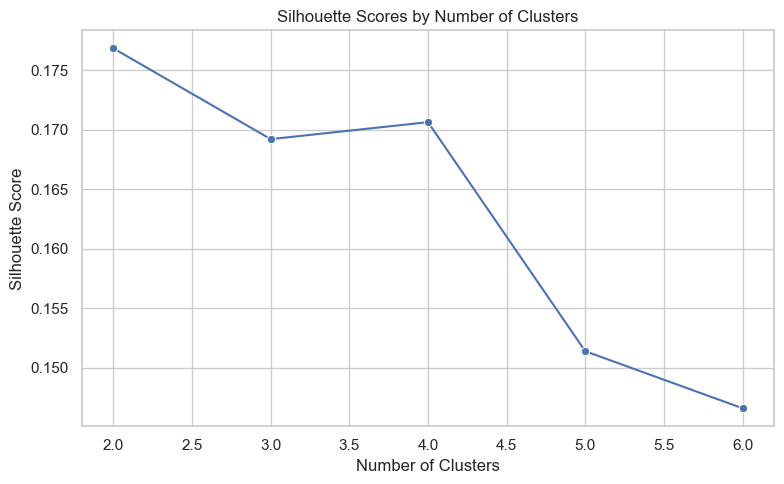

In [12]:
# ================================================================
# 6. SILHOUETTE ANALYSIS
# ================================================================

silhouette_results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

silhouette_df.to_csv(
    TABLE_DIR / "silhouette_scores.csv",
    index=False
)

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=silhouette_df,
    x="k",
    y="silhouette_score",
    marker="o"
)

plt.title("Silhouette Scores by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

save_figure("silhouette_scores.png")




In [13]:
# ================================================================
# 7. FINAL K-MEANS MODEL: FOUR CLUSTERS
# ================================================================

kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=20
)

team["cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = team.groupby("cluster")[
    FEATURES + ["epa_per_drive"]
].mean().round(3)

print("\nCluster Profiles:")
display(cluster_summary)

cluster_summary.to_csv(
    TABLE_DIR / "cluster_summary.csv"
)





Cluster Profiles:


C:\Users\jbenitez\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,pass_rate,early_down_pass_rate,success_rate,epa_per_play,fourth_down_go_rate,avg_air_yards,avg_yac,shotgun_rate,no_huddle_rate,epa_per_drive
cluster,,,,,,,,,,
0,0.525,0.478,0.444,0.023,0.020,8.604,5.068,0.766,0.129,0.152
1,0.608,0.554,0.407,-0.086,0.025,7.746,4.947,0.692,0.109,-0.482
2,0.551,0.499,0.457,0.058,0.019,7.592,5.701,0.557,0.072,0.352
3,0.625,0.581,0.462,0.061,0.017,8.041,5.218,0.684,0.074,0.380


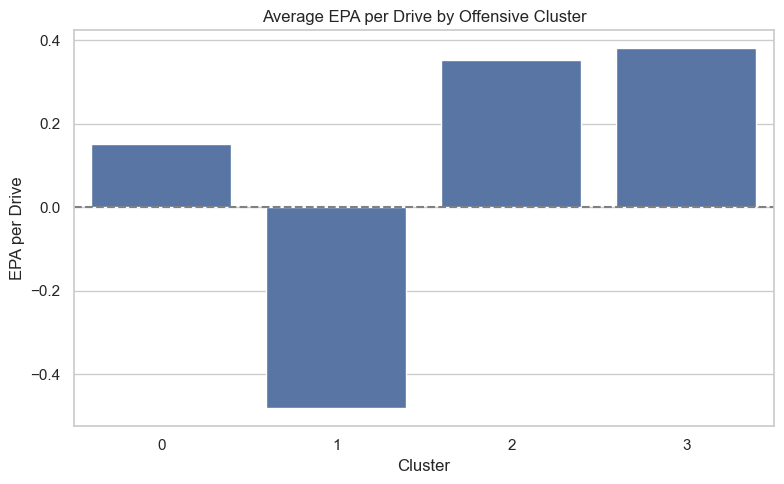

In [14]:
# ================================================================
# 8. CLUSTER EPA PER DRIVE
# ================================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=team,
    x="cluster",
    y="epa_per_drive",
    errorbar=None
)

plt.axhline(0, color="gray", linestyle="--")

plt.title("Average EPA per Drive by Offensive Cluster")
plt.xlabel("Cluster")
plt.ylabel("EPA per Drive")

save_figure("cluster_epa_per_drive.png")




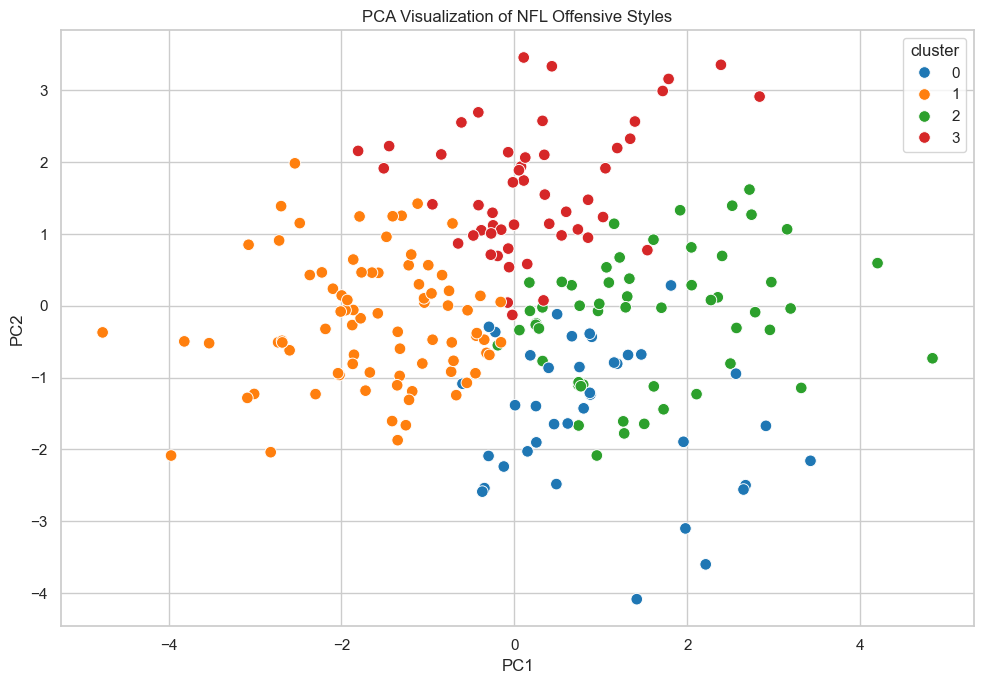

Variance explained by first two components: 49.79%


In [15]:
# ================================================================
# 9. PRINCIPAL COMPONENT ANALYSIS
# ================================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": team["cluster"].values,
    "team": team["posteam"].values,
    "season": team["season"].values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=70
)

plt.title("PCA Visualization of NFL Offensive Styles")

save_figure("pca_clusters.png")

print(
    "Variance explained by first two components:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)




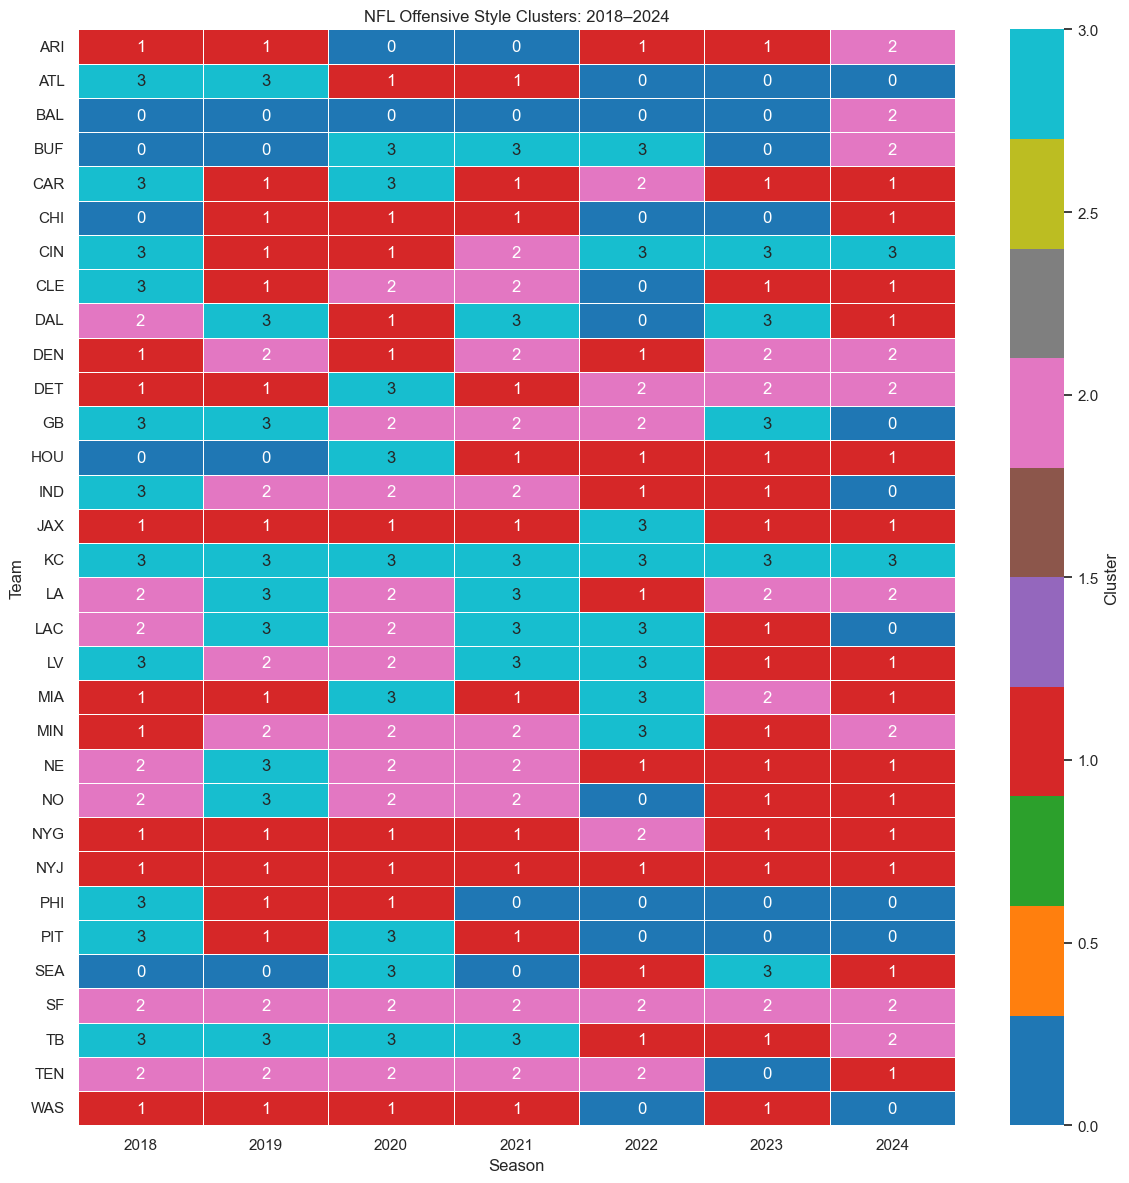

In [16]:
# ================================================================
# 10. CLUSTER TRANSITIONS BY TEAM AND SEASON
# ================================================================

cluster_grid = team.pivot(
    index="posteam",
    columns="season",
    values="cluster"
).sort_index()

plt.figure(figsize=(12, 12))

sns.heatmap(
    cluster_grid,
    annot=True,
    fmt=".0f",
    cmap="tab10",
    linewidths=0.5,
    cbar_kws={"label": "Cluster"}
)

plt.title("NFL Offensive Style Clusters: 2018–2024")
plt.xlabel("Season")
plt.ylabel("Team")

save_figure("cluster_transitions.png")

cluster_grid.to_csv(
    TABLE_DIR / "team_cluster_grid.csv"
)




In [17]:
# ================================================================
# 11. YEAR-TO-YEAR CLUSTER STABILITY
# ================================================================

transitions = team.sort_values(
    ["posteam", "season"]
).copy()

transitions["previous_cluster"] = (
    transitions.groupby("posteam")["cluster"].shift()
)

transitions["previous_season"] = (
    transitions.groupby("posteam")["season"].shift()
)

valid_transitions = transitions[
    transitions["season"]
    - transitions["previous_season"] == 1
].copy()

valid_transitions["stable"] = (
    valid_transitions["cluster"]
    == valid_transitions["previous_cluster"]
)

stability_rate = valid_transitions["stable"].mean()

print(
    "\nYear-to-year cluster retention:",
    f"{stability_rate:.2%}"
)

valid_transitions.to_csv(
    TABLE_DIR / "cluster_transition_pairs.csv",
    index=False
)





Year-to-year cluster retention: 49.48%



RIDGE REGRESSION RESULTS
Mean CV R²: 0.9937
Mean CV MAE: 0.0281


,feature,standardized_coefficient
3,epa_per_play,0.519320
2,success_rate,0.014623
1,early_down_pass_rate,0.005482
6,avg_yac,0.005347
7,shotgun_rate,0.003001
5,avg_air_yards,0.002340
8,no_huddle_rate,-0.002951
4,fourth_down_go_rate,-0.003909
0,pass_rate,-0.007046


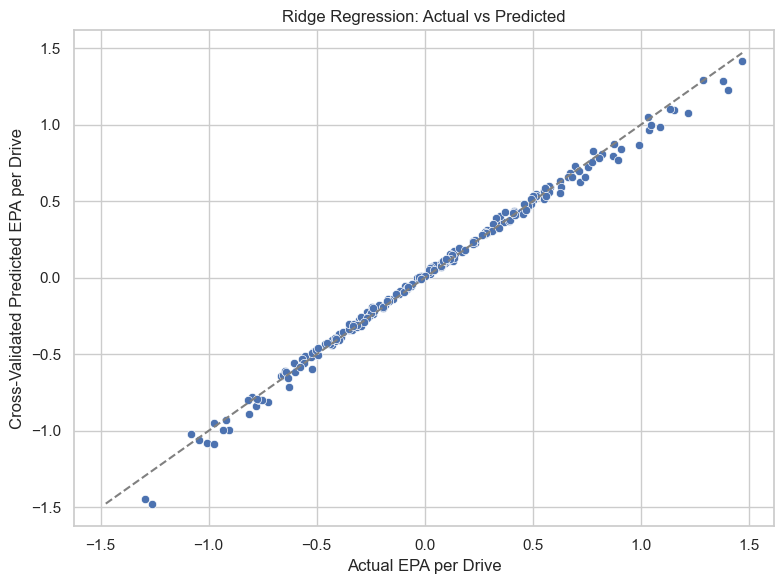

In [18]:
# ================================================================
# 12. RIDGE REGRESSION: SAME-SEASON EPA PER DRIVE
# ================================================================

X_reg = team[FEATURES].fillna(
    team[FEATURES].median()
)

y_reg = team["epa_per_drive"]

ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

cv = KFold(
    n_splits=7,
    shuffle=True,
    random_state=RANDOM_STATE
)

r2_scores = cross_val_score(
    ridge_pipeline,
    X_reg,
    y_reg,
    cv=cv,
    scoring="r2"
)

mae_scores = -cross_val_score(
    ridge_pipeline,
    X_reg,
    y_reg,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

cv_predictions = cross_val_predict(
    ridge_pipeline,
    X_reg,
    y_reg,
    cv=cv
)

print("\nRIDGE REGRESSION RESULTS")
print("Mean CV R²:", round(r2_scores.mean(), 4))
print("Mean CV MAE:", round(mae_scores.mean(), 4))

ridge_pipeline.fit(X_reg, y_reg)

coefficients = pd.DataFrame({
    "feature": FEATURES,
    "standardized_coefficient":
        ridge_pipeline.named_steps["ridge"].coef_
}).sort_values(
    "standardized_coefficient",
    ascending=False
)

display(coefficients)

coefficients.to_csv(
    TABLE_DIR / "ridge_coefficients.csv",
    index=False
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_reg,
    y=cv_predictions
)

minimum = min(y_reg.min(), cv_predictions.min())
maximum = max(y_reg.max(), cv_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="gray"
)

plt.xlabel("Actual EPA per Drive")
plt.ylabel("Cross-Validated Predicted EPA per Drive")
plt.title("Ridge Regression: Actual vs Predicted")

save_figure("ridge_predictions.png")

pd.DataFrame({
    "season": team["season"],
    "team": team["posteam"],
    "actual_epa_per_drive": y_reg,
    "predicted_epa_per_drive": cv_predictions
}).to_csv(
    TABLE_DIR / "ridge_cv_predictions.csv",
    index=False
)




In [19]:
# ================================================================
# 13. NEXT-SEASON EPA PREDICTION FROM CLUSTER MEMBERSHIP
# ================================================================

future = team.sort_values(
    ["posteam", "season"]
).copy()

future["next_epa_per_drive"] = (
    future.groupby("posteam")["epa_per_drive"].shift(-1)
)

future["next_season"] = (
    future.groupby("posteam")["season"].shift(-1)
)

future = future[
    future["next_season"] - future["season"] == 1
].copy()

X_future = pd.get_dummies(
    future["cluster"].astype(int),
    prefix="cluster",
    drop_first=True
).astype(float)

y_future = future["next_epa_per_drive"]

future_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

future_model = Ridge(alpha=1.0)

future_r2 = cross_val_score(
    future_model,
    X_future,
    y_future,
    cv=future_cv,
    scoring="r2"
)

future_mae = -cross_val_score(
    future_model,
    X_future,
    y_future,
    cv=future_cv,
    scoring="neg_mean_absolute_error"
)

print("\nNEXT-SEASON PREDICTION")
print("Mean R²:", round(future_r2.mean(), 4))
print("Mean MAE:", round(future_mae.mean(), 4))

pd.DataFrame({
    "fold": range(1, 6),
    "r2": future_r2,
    "mae": future_mae
}).to_csv(
    TABLE_DIR / "next_season_cv.csv",
    index=False
)





NEXT-SEASON PREDICTION
Mean R²: 0.0509
Mean MAE: 0.4212



PLAYOFF APPEARANCE BY CLUSTER


,team_seasons,playoff_appearances,playoff_rate
cluster,,,
0,38,23,0.605263
1,81,10,0.123457
2,54,32,0.592593
3,51,29,0.568627


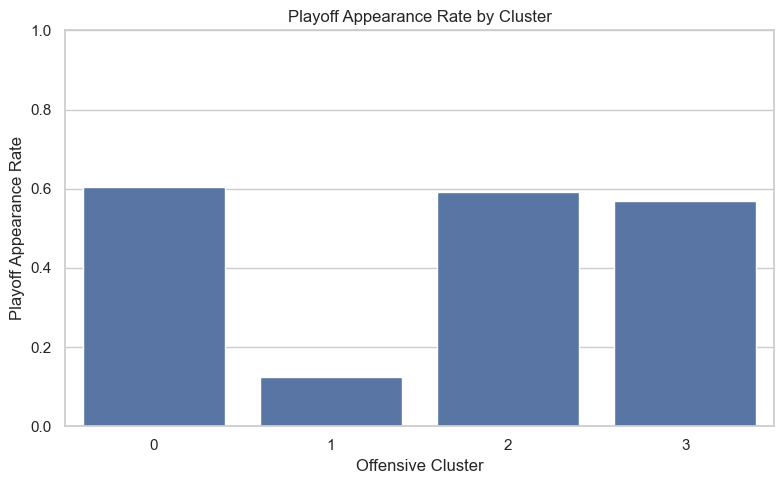

In [20]:
# ================================================================
# 14. PLAYOFF APPEARANCE ANALYSIS
# ================================================================

postseason = pbp[
    pbp["season_type"] == "POST"
][["season", "posteam", "defteam"]]

offensive_teams = postseason[
    ["season", "posteam"]
].rename(columns={"posteam": "team"})

defensive_teams = postseason[
    ["season", "defteam"]
].rename(columns={"defteam": "team"})

playoff_teams = pd.concat(
    [offensive_teams, defensive_teams],
    ignore_index=True
).dropna().drop_duplicates()

playoff_teams["playoff"] = 1

team_playoffs = team.merge(
    playoff_teams.rename(columns={"team": "posteam"}),
    on=["season", "posteam"],
    how="left",
    validate="one_to_one"
)

team_playoffs["playoff"] = (
    team_playoffs["playoff"].fillna(0).astype(int)
)

playoff_summary = team_playoffs.groupby(
    "cluster"
).agg(
    team_seasons=("playoff", "size"),
    playoff_appearances=("playoff", "sum"),
    playoff_rate=("playoff", "mean")
)

print("\nPLAYOFF APPEARANCE BY CLUSTER")
display(playoff_summary)

playoff_summary.to_csv(
    TABLE_DIR / "playoff_rate_by_cluster.csv"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=team_playoffs,
    x="cluster",
    y="playoff",
    errorbar=None
)

plt.title("Playoff Appearance Rate by Cluster")
plt.xlabel("Offensive Cluster")
plt.ylabel("Playoff Appearance Rate")
plt.ylim(0, 1)

save_figure("playoff_rate_by_cluster.png")




In [22]:
# ================================================================
# 15. EXPORT FINAL DATASET
# ================================================================

#team_playoffs.to_csv(
#    TABLE_DIR / "team_season_final.csv",
#    index=False
#)

print("\n" + "=" * 60)
print("PROJECT COMPLETE")
print("=" * 60)

print("Seasons analyzed: 2018–2024")
print("Team-seasons:", len(team))
print("Number of clusters:", team["cluster"].nunique())
print("Cluster retention:", f"{stability_rate:.2%}")
print("Ridge CV R²:", round(r2_scores.mean(), 4))
print("Ridge CV MAE:", round(mae_scores.mean(), 4))
print("Next-season CV R²:", round(future_r2.mean(), 4))
print("Next-season CV MAE:", round(future_mae.mean(), 4))
print("Results saved to:", OUTPUT_DIR)

print("\nNote: Same-season regression is descriptive.")
print("Playoff associations do not establish causation.")



PROJECT COMPLETE
Seasons analyzed: 2018–2024
Team-seasons: 224
Number of clusters: 4
Cluster retention: 49.48%
Ridge CV R²: 0.9937
Ridge CV MAE: 0.0281
Next-season CV R²: 0.0509
Next-season CV MAE: 0.4212
Results saved to: C:\Users\jbenitez\Downloads\Data Mining NFL Project\nfl_project_outputs

Note: Same-season regression is descriptive.
Playoff associations do not establish causation.
